# Baseline: regresión logística con y sin balanceo de clases

**Inteligencia Artificial Aplicada (1INF62) — Pontificia Universidad Católica del Perú, 2026-2**

**Integrantes:** Aguilera, Jair · Araujo, Luis · Condori, Nilton · Vilcayauri, Pedro

---

### Abstract

Este notebook establece el modelo de referencia (baseline) para predecir el bajo peso al nacer (< 2500 g) con el registro de Certificados de Nacido Vivo (CNV) del MINSA. Siguiendo el diseño de Almeida et al. (2026), se entrena una regresión logística sin balanceo y con balanceo de clases (`class_weight="balanced"`), y se evalúa con sus mismas métricas: accuracy, precisión, recall, F1-score y AUC-ROC. Los datos se preparan con `src/preprocessing.py`, que implementa las decisiones del EDA, y se dividen una sola vez en entrenamiento (3 489 993 registros) y test (872 499), con una prevalencia de bajo peso de 6.37% en ambos. Los modelos se evalúan en dos escenarios sobre el mismo conjunto de test: A, solo con información prenatal, y B, que agrega la duración del embarazo.

En ambos escenarios, el balanceo aumenta el recall a costa de la precisión, sin cambiar el AUC-ROC. En el Escenario A, el recall sube de 14.5% a 46.8% y la precisión baja de 59.8% a 11.2%, con un AUC-ROC de 0.654 en las dos versiones. En el Escenario B, el recall sube de 46.2% a 79.3% y el AUC-ROC alcanza 0.906. La diferencia entre escenarios confirma que la duración del embarazo concentra la mayor parte de la capacidad predictiva, y que con solo información prenatal la discriminación de la regresión logística es limitada. Estos valores son el punto de comparación para las siguientes etapas del proyecto.

### Estructura

1. Configuración del entorno
2. Carga y preparación de los datos
3. Partición train/test
4. Modelos
5. Evaluación
   - 5.1 Matrices de confusión
   - 5.2 Curvas ROC
6. Interpretación
7. Conclusiones

## 1. Configuración del entorno

El notebook está preparado para **Google Colab**. La primera celda clona el repositorio del proyecto (o lo actualiza, si ya estaba clonado en la sesión) e importa `src/preprocessing.py` desde ahí, de modo que siempre se usa la versión publicada en GitHub. Si no encuentra el módulo en el repositorio, usa como respaldo una copia subida manualmente a `/content/` e imprime un aviso.

Por defecto el notebook **no escribe archivos**: todos los resultados se muestran aquí. Con `GUARDAR_PROCESADO = True`, guarda el dataset limpio en `data/processed/cnv_limpio.csv.gz`.

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix,
                             roc_curve)

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if not IN_COLAB:
    raise RuntimeError("Este notebook está preparado para ejecutarse en Google Colab.")

REPO_URL = "https://github.com/jasnai10/AI_Project.git"
if not Path("/content/AI_Project").exists():
    !git clone -q {REPO_URL} /content/AI_Project
else:
    !git -C /content/AI_Project pull -q
ROOT = Path("/content/AI_Project/proyecto")

# Importación del preprocesamiento: primero desde el repositorio; si no está, desde una copia manual
RUTA_MODULO_REPO = ROOT / "src" / "preprocessing.py"
RUTA_MODULO_MANUAL = Path("/content/preprocessing.py")
if RUTA_MODULO_REPO.exists():
    sys.path.insert(0, str(ROOT))
    from src.preprocessing import (cargar_cnv, limpiar, seleccionar_features, columnas_features,
                                   dividir, construir_preprocesador, SEMILLA)
    print("preprocessing.py cargado desde el repositorio:", RUTA_MODULO_REPO)
elif RUTA_MODULO_MANUAL.exists():
    sys.path.insert(0, str(RUTA_MODULO_MANUAL.parent))
    from preprocessing import (cargar_cnv, limpiar, seleccionar_features, columnas_features,
                               dividir, construir_preprocesador, SEMILLA)
    print("AVISO: preprocessing.py cargado desde una copia manual:", RUTA_MODULO_MANUAL)
else:
    raise FileNotFoundError("No se encontró preprocessing.py: súbelo a GitHub (proyecto/src/) "
                            "o cárgalo manualmente en /content/")

GUARDAR_PROCESADO = False # Lo dejo en false debido a que ya se generó el dataset limpio y ya está
                          # en el github
RUTA_PROCESADO = ROOT / "data" / "processed" / "cnv_limpio.csv.gz"

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.4f}".format)

error: The following untracked working tree files would be overwritten by merge:
	proyecto/data/processed/cnv_limpio.csv.gz
Please move or remove them before you merge.
Aborting
preprocessing.py cargado desde el repositorio: /content/AI_Project/proyecto/src/preprocessing.py


## 2. Carga y preparación de los datos

Toda la limpieza se hace con `src/preprocessing.py`, que implementa las decisiones de la sección 10 del EDA. El notebook no aplica ninguna transformación propia, para que los modelos de las siguientes etapas trabajen exactamente con los mismos datos.

In [2]:
df_raw, reporte_carga = cargar_cnv(ruta_zip=ROOT / "data" / "raw" / "dataset.zip")
df = limpiar(df_raw)
del df_raw   # libera memoria

if GUARDAR_PROCESADO:
    RUTA_PROCESADO.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(RUTA_PROCESADO, index_label="id_registro", compression="gzip")
    print(f"Dataset limpio guardado en {RUTA_PROCESADO} ({RUTA_PROCESADO.stat().st_size / 1e6:.1f} MB)")

Cargado CNV_MINSA_CORTE_30112025.csv: 4,874,510 filas, 22 columnas | filas reparadas: 388 | descartadas: 0
limpiar(): 4,874,510 → 4,871,486 filas (eliminadas 3,024 sin peso válido) | prevalencia de bajo peso: 6.38%


## 3. Partición train/test

Los dos escenarios deben evaluarse **sobre exactamente los mismos registros**; si no, una diferencia en las métricas podría deberse a que cambió el conjunto de test y no a la variable agregada. Por eso:

1. Se seleccionan los casos completos con las features del Escenario B, que contiene todas las del A más `DUR_EMB_PARTO`.
2. Se hace un único split 80/20, estratificado por `bajo_peso` y con semilla fija.
3. Cada escenario toma sus columnas de esa misma partición.

In [3]:
X_B, y = seleccionar_features(df, escenario="B", target="bajo_peso")
X_train_B, X_test_B, y_train, y_test = dividir(X_B, y)

cat_A, num_A = columnas_features("A")
X_train = {"A": X_train_B[cat_A + num_A], "B": X_train_B}
X_test = {"A": X_test_B[cat_A + num_A], "B": X_test_B}

resumen_split = pd.DataFrame({
    "registros": [len(y_train), len(y_test)],
    "casos_bajo_peso": [int(y_train.sum()), int(y_test.sum())],
    "prevalencia_%": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["train", "test"])
display(resumen_split)
print("Features Escenario A:", cat_A + num_A)
print("Features Escenario B: las del A +", [c for c in X_train["B"].columns if c not in X_train["A"].columns])

Escenario B | target=bajo_peso | 10 features | casos completos: 4,362,492 de 4,871,486 (89.6%)


,registros,casos_bajo_peso,prevalencia_%
train,3489993,222431,6.3734
test,872499,55608,6.3734


Features Escenario A: ['Nivel_Instruccion', 'Financiador_Parto', 'Tipo_Parto', 'sexo_nacido', 'departamento', 'pais_grupo', 'edad_grupo', 'Num_embar_madre', 'nacmuer_abort_madre']
Features Escenario B: las del A + ['DUR_EMB_PARTO']


## 4. Modelos

Se entrenan dos versiones de regresión logística por escenario, siguiendo el diseño de Almeida et al. (2026). Cada una es un `Pipeline` que incluye el preprocesador, de modo que la codificación y el escalado se ajustan **solo con el conjunto de entrenamiento**.

| Modelo | Descripción |
|---|---|
| RL sin balanceo | Regresión logística con todas las observaciones con el mismo peso. |
| RL balanceada | Regresión logística con `class_weight="balanced"`: cada observación pesa de forma inversamente proporcional a la frecuencia de su clase, así que los casos de bajo peso cuentan más en el entrenamiento. |

Ambas usan la configuración por defecto de scikit-learn (regularización L2 con `C=1`), sin ajuste de hiperparámetros.

In [4]:
def crear_modelos(escenario):
    return {
        "RL sin balanceo": make_pipeline(construir_preprocesador(escenario),
                                         LogisticRegression(max_iter=1000, random_state=SEMILLA)),
        "RL balanceada": make_pipeline(construir_preprocesador(escenario),
                                       LogisticRegression(max_iter=1000, class_weight="balanced",
                                                          random_state=SEMILLA)),
    }

modelos, probas = {}, {}
for esc in ["A", "B"]:
    for nombre, modelo in crear_modelos(esc).items():
        t0 = time.time()
        modelo.fit(X_train[esc], y_train)
        modelos[(esc, nombre)] = modelo
        probas[(esc, nombre)] = modelo.predict_proba(X_test[esc])[:, 1]
        print(f"Escenario {esc} | {nombre:<16} entrenado en {time.time() - t0:5.1f} s")

Escenario A | RL sin balanceo  entrenado en  24.6 s
Escenario A | RL balanceada    entrenado en  30.1 s
Escenario B | RL sin balanceo  entrenado en  17.9 s
Escenario B | RL balanceada    entrenado en  27.9 s


## 5. Evaluación

Se usan las mismas métricas que Almeida et al. (2026), calculadas sobre el conjunto de test:

- **Accuracy:** proporción de predicciones correctas.
- **Precisión:** de los casos que el modelo marca como bajo peso, qué proporción lo es realmente.
- **Recall (sensibilidad):** de los recién nacidos con bajo peso, qué proporción detecta el modelo.
- **F1-score:** media armónica de precisión y recall.
- **AUC-ROC:** capacidad del modelo para distinguir entre ambas clases, independiente del umbral.

Las cuatro primeras usan el umbral por defecto de 0.5.

In [5]:
def evaluar(y_true, p, umbral=0.5):
    pred = (p >= umbral).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "auc_roc": roc_auc_score(y_true, p),
    }

metricas = pd.DataFrame({k: evaluar(y_test, p) for k, p in probas.items()}).T
metricas.index.names = ["escenario", "modelo"]
display(metricas)

accuracy  precision  recall     f1  auc_roc
escenario modelo                                                      
A         RL sin balanceo    0.9393     0.5979  0.1447 0.2331   0.6535
          RL balanceada      0.7306     0.1123  0.4676 0.1812   0.6542
B         RL sin balanceo    0.9593     0.8220  0.4619 0.5914   0.9054
          RL balanceada      0.8763     0.3138  0.7929 0.4496   0.9063

### 5.1 Matrices de confusión

Cada celda muestra el número de registros del conjunto de test y, entre paréntesis, el porcentaje sobre la clase real (fila).

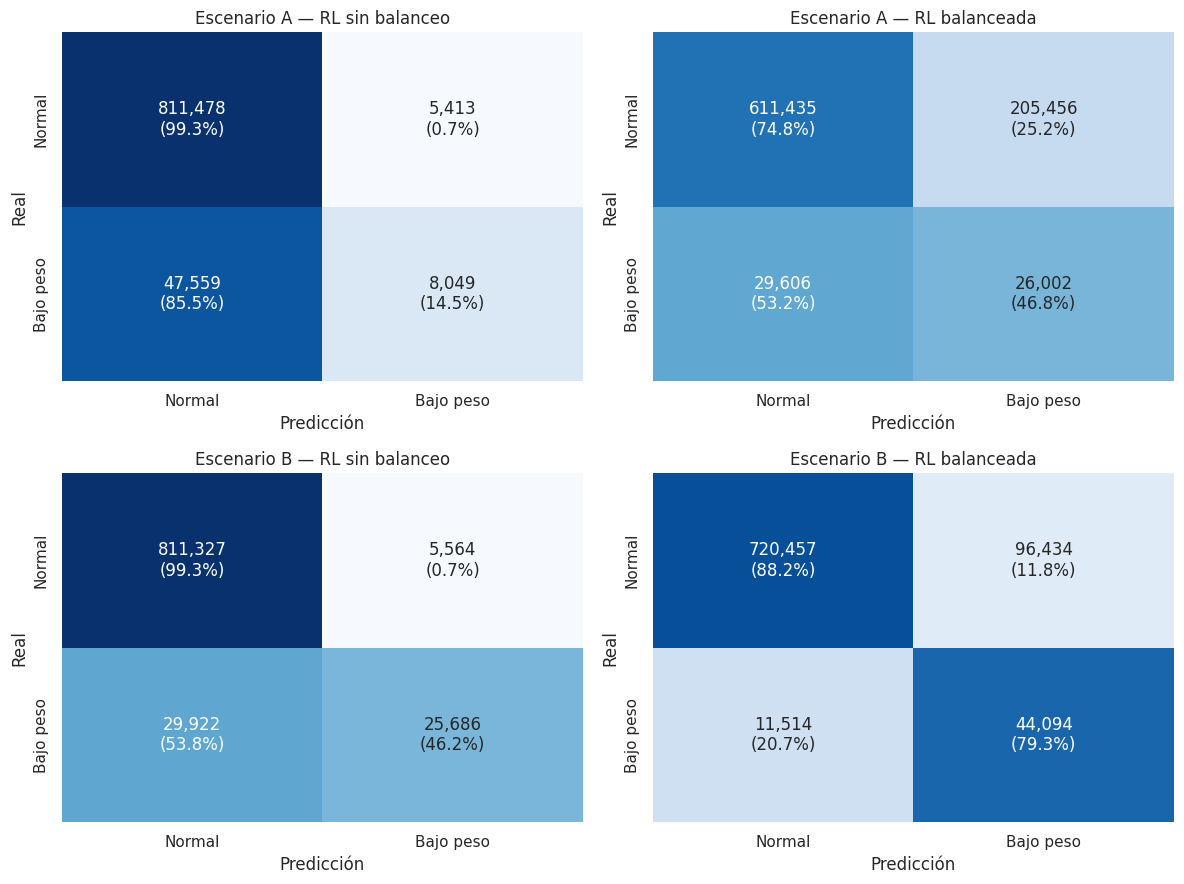

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for i, esc in enumerate(["A", "B"]):
    for j, nombre in enumerate(["RL sin balanceo", "RL balanceada"]):
        ax = axes[i, j]
        cm = confusion_matrix(y_test, (probas[(esc, nombre)] >= 0.5).astype(int), labels=[0, 1])
        pct = cm / cm.sum(axis=1, keepdims=True) * 100
        etiquetas = np.array([[f"{cm[r, c]:,}\n({pct[r, c]:.1f}%)" for c in range(2)] for r in range(2)])
        sns.heatmap(pct, annot=etiquetas, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax,
                    xticklabels=["Normal", "Bajo peso"], yticklabels=["Normal", "Bajo peso"])
        ax.set_title(f"Escenario {esc} — {nombre}")
        ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

### 5.2 Curvas ROC

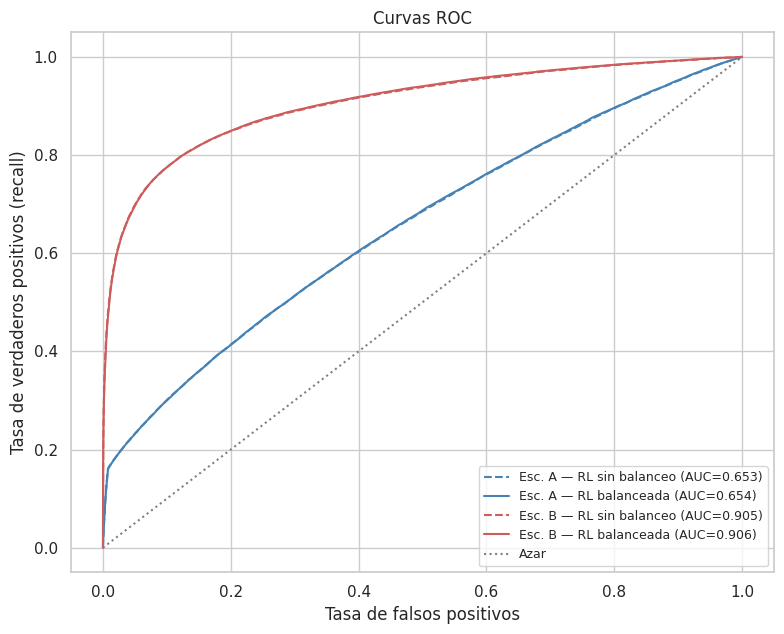

In [7]:
fig, ax = plt.subplots(figsize=(8, 6.5))
estilos = {"RL sin balanceo": "--", "RL balanceada": "-"}
colores = {"A": "steelblue", "B": "indianred"}
for esc in ["A", "B"]:
    for nombre, ls in estilos.items():
        p = probas[(esc, nombre)]
        fpr, tpr, _ = roc_curve(y_test, p)
        ax.plot(fpr, tpr, ls=ls, color=colores[esc],
                label=f"Esc. {esc} — {nombre} (AUC={roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], color="gray", ls=":", label="Azar")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("Curvas ROC"); ax.legend(fontsize=9, loc="lower right")
plt.tight_layout(); plt.show()

## 6. Interpretación

Las cifras salen de la tabla de métricas (sección 5) y de las matrices de confusión (sección 5.1).

**1. Sin balanceo, la accuracy es alta pero el modelo detecta pocos casos.** En el Escenario A, la regresión sin balanceo alcanza 93.9% de accuracy, pero su recall es de solo 14.5%: detecta 8 049 de los 55 608 casos de bajo peso del test. Con una prevalencia de 6.4% (sección 3), un modelo que nunca predijera bajo peso ya tendría 93.6% de accuracy, así que esa métrica, sola, no indica un buen desempeño.

**2. El balanceo aumenta el recall a costa de la precisión y la accuracy.**
- En el Escenario A, el recall sube de 14.5% a 46.8%, mientras la precisión baja de 59.8% a 11.2% y la accuracy de 93.9% a 73.1%.
- En el Escenario B, el recall sube de 46.2% a 79.3%, la precisión baja de 82.2% a 31.4% y la accuracy de 95.9% a 87.6%.
- El F1-score baja con el balanceo en ambos escenarios: de 0.233 a 0.181 en A y de 0.591 a 0.450 en B.

**3. El AUC-ROC no cambia con el balanceo.** Es 0.654 sin balanceo y 0.654 con balanceo en el Escenario A, y 0.905 frente a 0.906 en el B. Como el AUC-ROC no depende del umbral, esto indica que el balanceo no mejora la capacidad del modelo para distinguir entre clases: lo que cambia es la clasificación que resulta al aplicar el umbral de 0.5.

**4. El aumento del recall tiene un costo alto en falsos positivos.** En el Escenario A, la regresión balanceada detecta 26 002 casos de bajo peso, pero genera 205 456 falsos positivos. En el Escenario B detecta 44 094 casos con 96 434 falsos positivos.

**5. La duración del embarazo explica la mayor parte de la diferencia entre escenarios.** Agregar `DUR_EMB_PARTO` lleva el AUC-ROC de 0.654 a 0.905. Es coherente con lo anticipado en el EDA (sección 9), donde esa variable sola alcanzaba un AUC de 0.888.

## 7. Conclusiones

Los valores de referencia del baseline, sobre el conjunto de test, son:

| Escenario | Modelo | Recall | F1-score | AUC-ROC |
|---|---|---|---|---|
| A (prenatal) | RL sin balanceo | 0.145 | 0.233 | 0.654 |
| A (prenatal) | RL balanceada | 0.468 | 0.181 | 0.654 |
| B (con duración del embarazo) | RL sin balanceo | 0.462 | 0.591 | 0.905 |
| B (con duración del embarazo) | RL balanceada | 0.793 | 0.450 | 0.906 |

- El balanceo de clases aumenta el recall en ambos escenarios, pero no mejora el AUC-ROC.
- Con solo información prenatal (Escenario A), la capacidad de discriminación de la regresión logística es limitada (AUC-ROC de 0.654).

### Limitaciones de este baseline

- Hiperparámetros por defecto (regularización L2 con `C=1`), sin ajuste.
- Umbral de decisión fijo en 0.5.
- Una sola partición train/test, sin validación cruzada.
- `Num_embar_madre` y `nacmuer_abort_madre` entran como variables numéricas, por lo que la regresión solo puede capturar un efecto lineal de ellas.